# EDA và tiền xử lý dữ liệu Wine Quality

Notebook thực hiện khảo sát và tiền xử lý bộ dữ liệu Wine Quality gồm rượu vang đỏ và trắng. Kết quả được lưu tại `output/wine_quality_clean.csv`.

**Bài toán:** phân loại đa lớp chất lượng rượu vang thành ba nhóm:
- **Thấp:** `quality <= 5`
- **Trung bình:** `quality == 6`
- **Cao:** `quality >= 7`

Nhãn số tương ứng: Thấp = 0, Trung bình = 1, Cao = 2. Cột `quality` gốc được giữ để phân tích, nhưng không được đưa vào tập đặc trưng khi huấn luyện mô hình cùng với `quality_group`/`label`.

## 1. Import thư viện, khai báo đường dẫn và đọc dữ liệu

In [25]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

# Tìm thư mục dự án dựa trên các tệp dữ liệu mong đợi.
candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in candidate_roots
     if (p / "data" / "winequality-red.csv").is_file()
     and (p / "data" / "winequality-white.csv").is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy data/winequality-red.csv và data/winequality-white.csv. "
        "Hãy đặt notebook trong thư mục notebooks/ của dự án hoặc cập nhật PROJECT_ROOT."
    )

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

red_path = DATA_DIR / "winequality-red.csv"
white_path = DATA_DIR / "winequality-white.csv"

red = pd.read_csv(red_path, sep=";")
white = pd.read_csv(white_path, sep=";")
red["wine_type"] = "red"
white["wine_type"] = "white"
df_raw = pd.concat([red, white], ignore_index=True)

print("Thư mục dự án:", PROJECT_ROOT)
print("Nguồn dữ liệu đỏ:", red_path)
print("Nguồn dữ liệu trắng:", white_path)
print("Kích thước rượu đỏ:", red.shape)
print("Kích thước rượu trắng:", white.shape)
print("Kích thước dữ liệu gộp:", df_raw.shape)
display(df_raw.head())

Thư mục dự án: d:\ML-report
Nguồn dữ liệu đỏ: d:\ML-report\data\winequality-red.csv
Nguồn dữ liệu trắng: d:\ML-report\data\winequality-white.csv
Kích thước rượu đỏ: (1599, 13)
Kích thước rượu trắng: (4898, 13)
Kích thước dữ liệu gộp: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## 2. Khảo sát nguồn, quy mô, kiểu dữ liệu và từ điển dữ liệu

### Nguồn và điều kiện sử dụng

Nguồn dự kiến: **UCI Machine Learning Repository – Wine Quality** (dữ liệu rượu vang đỏ và trắng, nghiên cứu tại miền bắc Bồ Đào Nha). Trang nguồn: https://archive.ics.uci.edu/dataset/186/wine+quality

Bộ dữ liệu UCI được cung cấp theo giấy phép **CC BY 4.0**; khi sử dụng trong báo cáo, cần ghi nguồn và trích dẫn bài báo/bộ dữ liệu gốc theo hướng dẫn trên trang UCI. Nếu nhóm tải dữ liệu từ một nguồn khác, hãy ghi đúng nguồn thực tế đã sử dụng.

In [14]:
print("Số mẫu:", len(df_raw))
print("Số cột:", df_raw.shape[1])
print("\nKiểu dữ liệu:")
display(df_raw.dtypes.astype(str).to_frame("data_type"))
print("\nThông tin tổng quan:")
df_raw.info()

Số mẫu: 6497
Số cột: 13

Kiểu dữ liệu:


,data_type
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64



Thông tin tổng quan:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [15]:
# Từ điển dữ liệu: mô tả các cột chuẩn của Wine Quality.
data_dictionary = pd.DataFrame([
    ("fixed acidity", "Độ axit cố định", "g/dm³", "Đặc trưng đầu vào"),
    ("volatile acidity", "Độ axit bay hơi", "g/dm³", "Đặc trưng đầu vào"),
    ("citric acid", "Axit citric", "g/dm³", "Đặc trưng đầu vào"),
    ("residual sugar", "Lượng đường dư", "g/dm³", "Đặc trưng đầu vào"),
    ("chlorides", "Nồng độ chloride", "g/dm³", "Đặc trưng đầu vào"),
    ("free sulfur dioxide", "Lượng sulfur dioxide tự do", "mg/dm³", "Đặc trưng đầu vào"),
    ("total sulfur dioxide", "Lượng sulfur dioxide tổng", "mg/dm³", "Đặc trưng đầu vào"),
    ("density", "Khối lượng riêng", "g/cm³", "Đặc trưng đầu vào"),
    ("pH", "Độ pH", "không đơn vị", "Đặc trưng đầu vào"),
    ("sulphates", "Nồng độ sulphates", "g/dm³", "Đặc trưng đầu vào"),
    ("alcohol", "Nồng độ cồn", "% thể tích", "Đặc trưng đầu vào"),
    ("quality", "Điểm chất lượng cảm quan gốc", "thang điểm", "Biến mục tiêu gốc"),
    ("wine_type", "Loại rượu: đỏ hoặc trắng", "red/white", "Đặc trưng phân loại bổ sung"),
], columns=["column", "meaning", "unit", "role"])
display(data_dictionary)

,column,meaning,unit,role
0,fixed acidity,Độ axit cố định,g/dm³,Đặc trưng đầu vào
1,volatile acidity,Độ axit bay hơi,g/dm³,Đặc trưng đầu vào
2,citric acid,Axit citric,g/dm³,Đặc trưng đầu vào
3,residual sugar,Lượng đường dư,g/dm³,Đặc trưng đầu vào
4,chlorides,Nồng độ chloride,g/dm³,Đặc trưng đầu vào
5,free sulfur dioxide,Lượng sulfur dioxide tự do,mg/dm³,Đặc trưng đầu vào
6,total sulfur dioxide,Lượng sulfur dioxide tổng,mg/dm³,Đặc trưng đầu vào
7,density,Khối lượng riêng,g/cm³,Đặc trưng đầu vào
8,pH,Độ pH,không đơn vị,Đặc trưng đầu vào
9,sulphates,Nồng độ sulphates,g/dm³,Đặc trưng đầu vào


## 3. Thống kê mô tả

In [16]:
numeric_cols = df_raw.select_dtypes(include=np.number).columns.tolist()
display(df_raw[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


## 4. Phân tích phân bố đặc trưng và nhãn

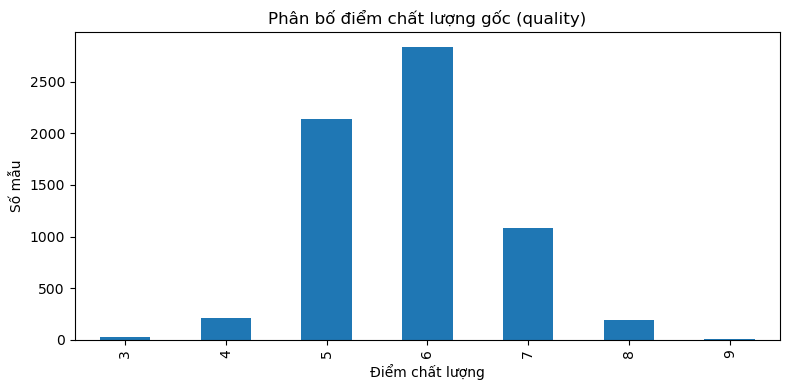

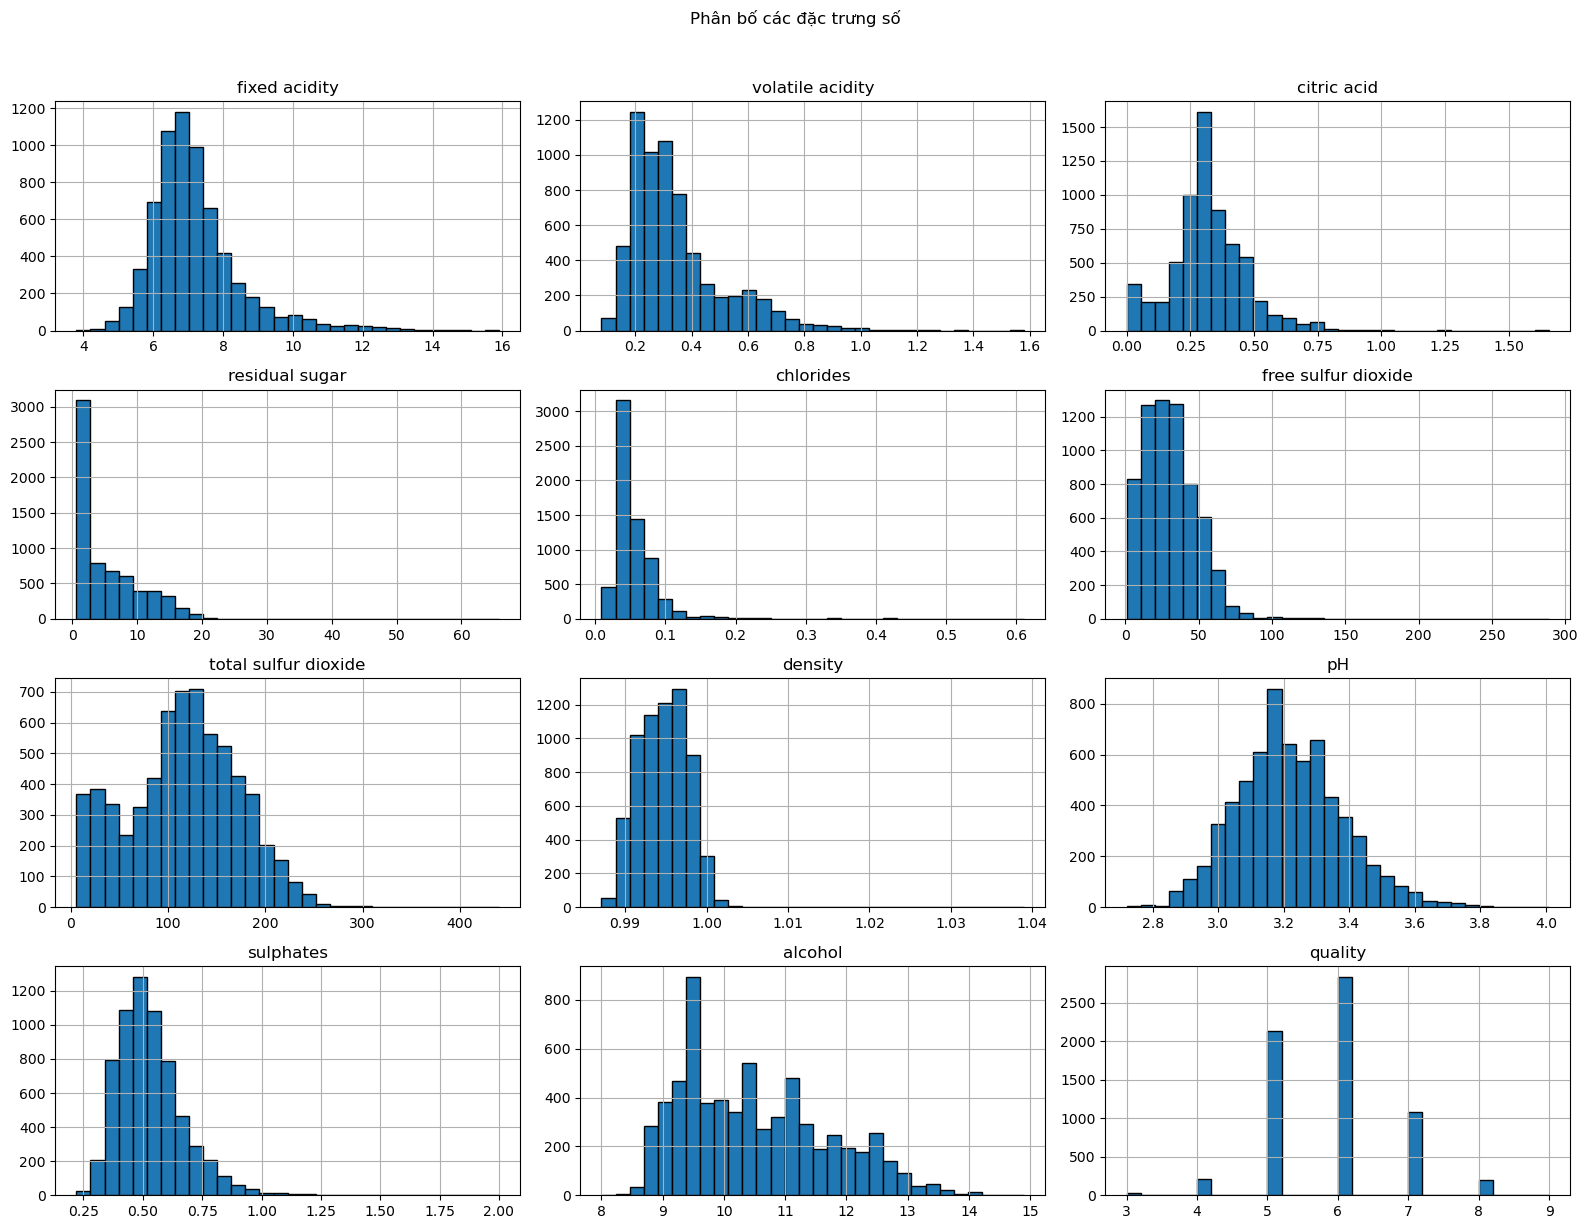

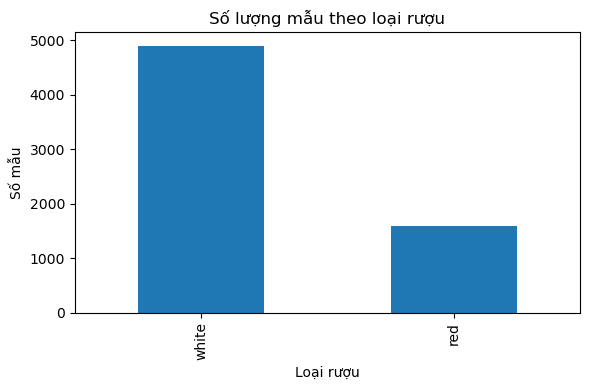

In [17]:
# Phân bố điểm chất lượng gốc
fig, ax = plt.subplots(figsize=(8, 4))
df_raw["quality"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Phân bố điểm chất lượng gốc (quality)")
ax.set_xlabel("Điểm chất lượng")
ax.set_ylabel("Số mẫu")
plt.tight_layout()
plt.show()

# Phân bố các đặc trưng số bằng histogram
df_raw[numeric_cols].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Phân bố các đặc trưng số", y=1.02)
plt.tight_layout()
plt.show()

# Phân bố theo loại rượu
fig, ax = plt.subplots(figsize=(6, 4))
df_raw["wine_type"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Số lượng mẫu theo loại rượu")
ax.set_xlabel("Loại rượu")
ax.set_ylabel("Số mẫu")
plt.tight_layout()
plt.show()

## 5. Phân tích quan hệ đặc trưng – nhãn, kèm nhận xét

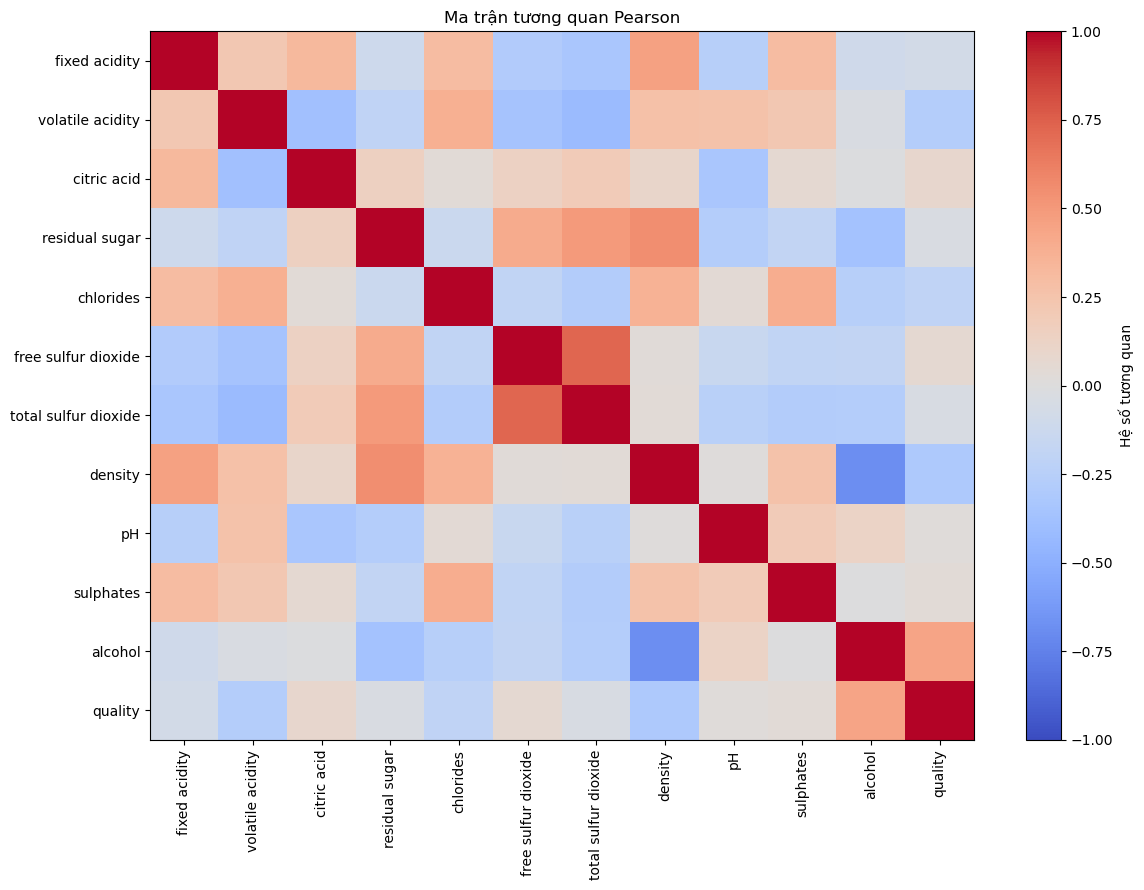

,correlation_with_quality
density,-0.305858
volatile acidity,-0.265699
chlorides,-0.200666
fixed acidity,-0.076743
total sulfur dioxide,-0.041385
residual sugar,-0.036980
pH,0.019506
sulphates,0.038485
free sulfur dioxide,0.055463
citric acid,0.085532


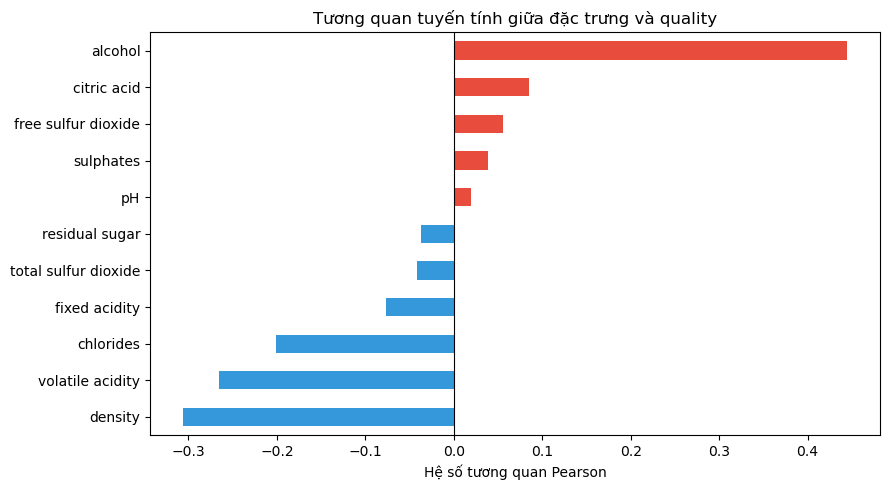

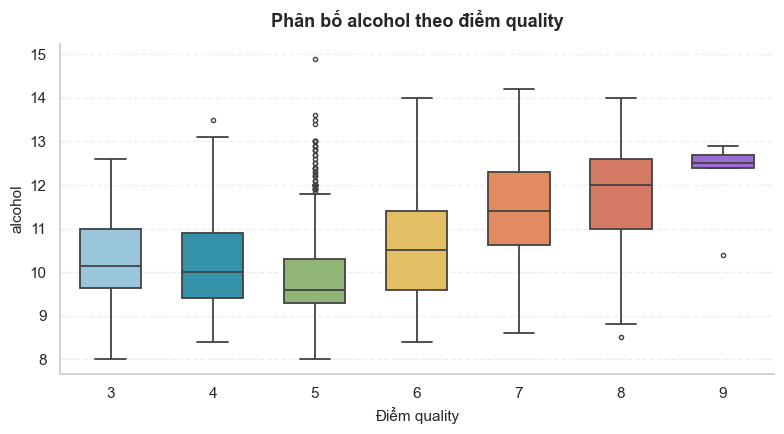

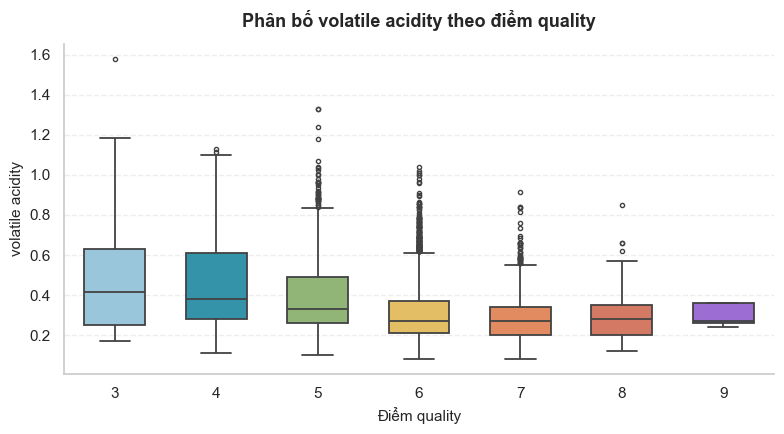

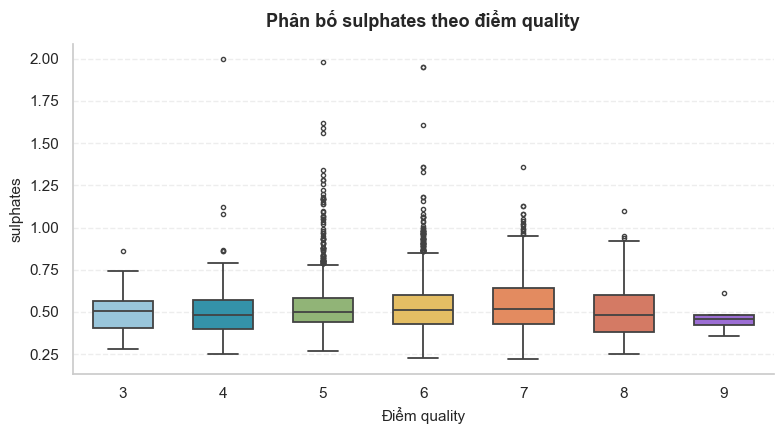

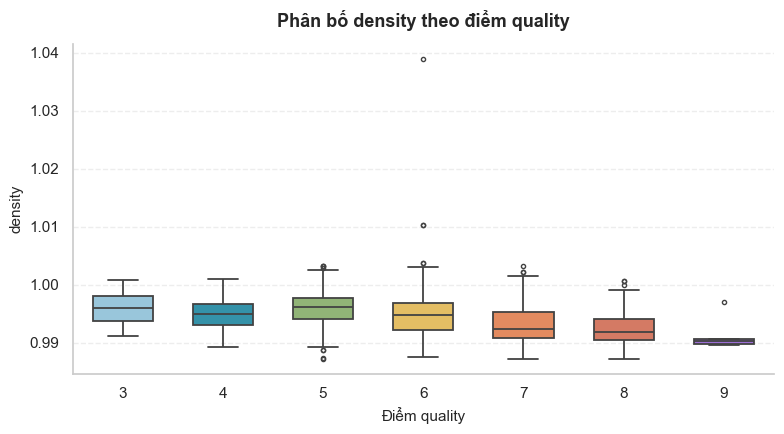

In [28]:
# Tương quan giữa các biến số
corr = df_raw[numeric_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title("Ma trận tương quan Pearson")
fig.colorbar(im, ax=ax, label="Hệ số tương quan")
plt.tight_layout()
plt.show()

# Tương quan với quality để sắp xếp các quan hệ tuyến tính nổi bật
quality_corr = corr["quality"].drop("quality").sort_values()
display(quality_corr.to_frame("correlation_with_quality"))

colors = ["#3498DB" if value < 0 else "#E74C3C"
          for value in quality_corr]

fig, ax = plt.subplots(figsize=(9, 5))
quality_corr.plot(kind="barh", ax=ax, color=colors)

ax.set_title("Tương quan tuyến tính giữa đặc trưng và quality")
ax.set_xlabel("Hệ số tương quan Pearson")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# Boxplot các đặc trưng tiêu biểu theo điểm chất lượng
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="Set2")

palette = ["#8ECAE6", "#219EBC", "#90BE6D",
           "#F9C74F", "#F9844A", "#E76F51", "#9B5DE5"]

for col in ["alcohol", "volatile acidity", "sulphates", "density"]:
    fig, ax = plt.subplots(figsize=(8, 4.5))

    sns.boxplot(
        data=df_raw,
        x="quality",
        y=col,
        hue="quality",
        palette=palette,
        legend=False,
        width=0.6,
        linewidth=1.3,
        fliersize=3,
        ax=ax
    )

    ax.set_title(
        f"Phân bố {col} theo điểm quality",
        fontsize=13,
        fontweight="bold",
        pad=12
    )
    ax.set_xlabel("Điểm quality", fontsize=11)
    ax.set_ylabel(col, fontsize=11)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    sns.despine()
    plt.tight_layout()
    plt.show()

## 6. Kiểm tra dữ liệu thiếu, trùng, ngoại lai, sai định dạng

In [29]:
# Kiểm tra dữ liệu thiếu
missing_report = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(3)
}).sort_values("missing_count", ascending=False)
display(missing_report)

# Kiểm tra bản ghi trùng hoàn toàn
duplicate_count = int(df_raw.duplicated().sum())
print(f"Số bản ghi trùng hoàn toàn: {duplicate_count} / {len(df_raw)} "
      f"({duplicate_count / max(len(df_raw), 1) * 100:.2f}%)")

# Kiểm tra giá trị không phải số/sai định dạng ở các cột số
numeric_check = df_raw[numeric_cols].apply(pd.to_numeric, errors="coerce")
invalid_numeric = numeric_check.isna().sum() - df_raw[numeric_cols].isna().sum()
display(invalid_numeric.rename("invalid_non_numeric_count").to_frame())

# Phát hiện ngoại lai theo quy tắc IQR; chỉ thống kê, chưa tự động xóa
outlier_rows = []
for col in numeric_cols:
    s = pd.to_numeric(df_raw[col], errors="coerce").dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append((col, lower, upper, count, count / max(len(s), 1) * 100))
outlier_report = pd.DataFrame(outlier_rows, columns=[
    "feature", "IQR_lower_bound", "IQR_upper_bound", "outlier_count", "outlier_percent"
]).sort_values("outlier_count", ascending=False)
display(outlier_report)

,missing_count,missing_percent
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0


Số bản ghi trùng hoàn toàn: 1177 / 6497 (18.12%)


,invalid_non_numeric_count
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


,feature,IQR_lower_bound,IQR_upper_bound,outlier_count,outlier_percent
2,citric acid,0.040000,0.600000,509,7.834385
1,volatile acidity,-0.025000,0.655000,377,5.802678
0,fixed acidity,4.450000,9.650000,357,5.494844
4,chlorides,-0.002500,0.105500,286,4.402032
11,quality,3.500000,7.500000,228,3.509312
9,sulphates,0.175000,0.855000,191,2.939818
3,residual sugar,-7.650000,17.550000,118,1.816223
8,pH,2.795000,3.635000,73,1.123596
5,free sulfur dioxide,-19.000000,77.000000,62,0.954287
6,total sulfur dioxide,-41.500000,274.500000,10,0.153917


## 7. Kiểm tra mất cân bằng nhãn và nguy cơ rò rỉ dữ liệu

,count,percent
quality,,
3,30,0.46
4,216,3.32
5,2138,32.91
6,2836,43.65
7,1079,16.61
8,193,2.97
9,5,0.08


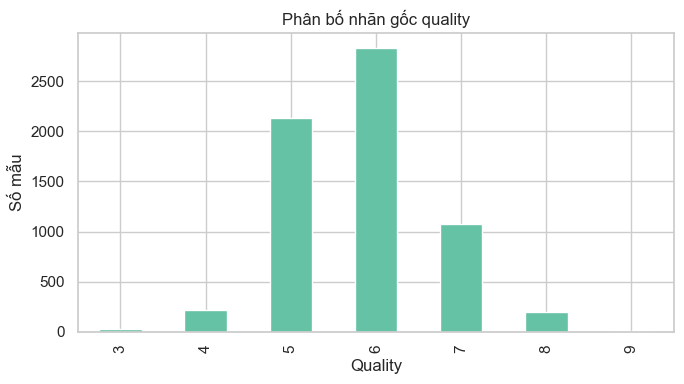

Cột mục tiêu gốc: quality
Các cột dẫn xuất mục tiêu sẽ tạo ở bước sau: quality_group, label
Khi huấn luyện, cần loại quality, quality_group và label khỏi X.
Nếu có nhiều bản ghi cùng một mẫu vật/nguồn đo, cần cân nhắc chia theo nhóm để tránh cùng nhóm xuất hiện ở train và test.


In [30]:
quality_counts = df_raw["quality"].value_counts().sort_index()
quality_pct = (quality_counts / quality_counts.sum() * 100).round(2)
display(pd.DataFrame({"count": quality_counts, "percent": quality_pct}))

fig, ax = plt.subplots(figsize=(7, 4))
quality_counts.plot(kind="bar", ax=ax)
ax.set_title("Phân bố nhãn gốc quality")
ax.set_xlabel("Quality")
ax.set_ylabel("Số mẫu")
plt.tight_layout()
plt.show()

# Kiểm tra các cột có thể gây rò rỉ sau khi tạo nhãn:
print("Cột mục tiêu gốc:", "quality")
print("Các cột dẫn xuất mục tiêu sẽ tạo ở bước sau: quality_group, label")
print("Khi huấn luyện, cần loại quality, quality_group và label khỏi X.")
print("Nếu có nhiều bản ghi cùng một mẫu vật/nguồn đo, cần cân nhắc chia theo nhóm để tránh cùng nhóm xuất hiện ở train và test.")

## 8. Tiền xử lý dữ liệu

In [31]:
df_work = df_raw.copy()
rows_before = len(df_work)

# Ép kiểu số an toàn cho các cột số; giá trị không hợp lệ sẽ thành NaN và được báo cáo.
for col in numeric_cols:
    df_work[col] = pd.to_numeric(df_work[col], errors="coerce")

# Xóa dòng không có quality vì không thể tạo nhãn giám sát.
missing_quality_before = int(df_work["quality"].isna().sum())
df_work = df_work.dropna(subset=["quality"]).copy()

# Chỉ xóa bản ghi trùng hoàn toàn sau khi gộp dữ liệu đỏ/trắng.
duplicates_before_drop = int(df_work.duplicated().sum())
df_work = df_work.drop_duplicates().reset_index(drop=True)

# Với các đặc trưng còn thiếu, điền bằng trung vị của từng cột số.
# Việc điền ở đây chỉ tạo bộ dữ liệu EDA sạch; khi đánh giá mô hình,
# nên đặt imputer trong Pipeline và fit riêng trên tập huấn luyện.
feature_numeric_cols = [c for c in numeric_cols if c != "quality"]
missing_before_impute = df_work[feature_numeric_cols].isna().sum()
for col in feature_numeric_cols:
    if df_work[col].isna().any():
        median_value = df_work[col].median()
        df_work[col] = df_work[col].fillna(median_value)

# Loại các điểm quality ngoài thang điểm nguyên 0..10 nếu có.
valid_quality = (
    df_work["quality"].between(0, 10)
    & np.isclose(df_work["quality"], np.round(df_work["quality"]))
)
invalid_quality_count = int((~valid_quality).sum())
df_work = df_work.loc[valid_quality].copy()
df_work["quality"] = df_work["quality"].astype(int)

print("Số dòng ban đầu:", rows_before)
print("Dòng thiếu quality đã loại:", missing_quality_before)
print("Bản ghi trùng đã loại:", duplicates_before_drop)
print("Giá trị quality sai miền/không nguyên đã loại:", invalid_quality_count)
print("Số ô thiếu trước điền khuyết theo cột:")
display(missing_before_impute[missing_before_impute > 0].rename("missing_before_imputation").to_frame())
print("Kích thước sau tiền xử lý:", df_work.shape)
print("Số giá trị thiếu còn lại:", int(df_work.isna().sum().sum()))

Số dòng ban đầu: 6497
Dòng thiếu quality đã loại: 0
Bản ghi trùng đã loại: 1177
Giá trị quality sai miền/không nguyên đã loại: 0
Số ô thiếu trước điền khuyết theo cột:


,missing_before_imputation


Kích thước sau tiền xử lý: (5320, 13)
Số giá trị thiếu còn lại: 0


## 9. Tạo nhãn chất lượng ba mức: Thấp – Trung bình – Cao

In [22]:
def map_quality_group(q):
    if q <= 5:
        return "Thấp"
    elif q == 6:
        return "Trung bình"
    return "Cao"

label_map = {"Thấp": 0, "Trung bình": 1, "Cao": 2}
df_work["quality_group"] = df_work["quality"].map(map_quality_group)
df_work["label"] = df_work["quality_group"].map(label_map).astype("int64")

display(
    df_work[["quality", "quality_group", "label"]]
    .drop_duplicates()
    .sort_values("quality")
)
print("Phân bố nhãn sau khi tạo:")
display(pd.DataFrame({
    "count": df_work["quality_group"].value_counts(),
    "percent": (df_work["quality_group"].value_counts(normalize=True) * 100).round(2)
}))

,quality,quality_group,label
400,3,Thấp,0
16,4,Thấp,0
0,5,Thấp,0
3,6,Trung bình,1
6,7,Cao,2
235,8,Cao,2
2012,9,Cao,2


Phân bố nhãn sau khi tạo:


,count,percent
quality_group,,
Trung bình,2323,43.67
Thấp,1988,37.37
Cao,1009,18.97


## 10. So sánh dữ liệu trước và sau tiền xử lý

,before,after,change
rows,6497,5320,-1177
columns,13,15,2
missing_cells,0,0,0
duplicate_rows,1177,0,-1177


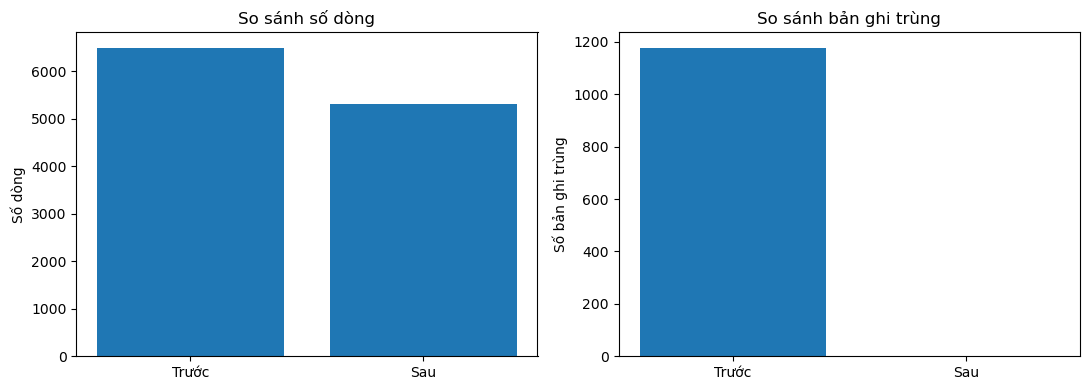

Phân bố nhãn trước xử lý (theo quality gốc):


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


Phân bố nhãn ba mức sau xử lý:


,count
quality_group,
Thấp,1988
Trung bình,2323
Cao,1009


In [23]:
comparison = pd.DataFrame({
    "before": {
        "rows": len(df_raw),
        "columns": df_raw.shape[1],
        "missing_cells": int(df_raw.isna().sum().sum()),
        "duplicate_rows": int(df_raw.duplicated().sum())
    },
    "after": {
        "rows": len(df_work),
        "columns": df_work.shape[1],
        "missing_cells": int(df_work.isna().sum().sum()),
        "duplicate_rows": int(df_work.duplicated().sum())
    }
})
comparison["change"] = comparison["after"] - comparison["before"]
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Trước", "Sau"], [len(df_raw), len(df_work)])
axes[0].set_title("So sánh số dòng")
axes[0].set_ylabel("Số dòng")
axes[1].bar(["Trước", "Sau"], [
    int(df_raw.duplicated().sum()),
    int(df_work.duplicated().sum())
])
axes[1].set_title("So sánh bản ghi trùng")
axes[1].set_ylabel("Số bản ghi trùng")
plt.tight_layout()
plt.show()

print("Phân bố nhãn trước xử lý (theo quality gốc):")
display(df_raw["quality"].value_counts().sort_index().rename("count").to_frame())
print("Phân bố nhãn ba mức sau xử lý:")
display(df_work["quality_group"].value_counts().reindex(["Thấp", "Trung bình", "Cao"]).rename("count").to_frame())

## 11. Lưu dữ liệu sạch vào `output/wine_quality_clean.csv`

In [24]:
output_path = OUTPUT_DIR / "wine_quality_clean.csv"
df_work.to_csv(output_path, index=False, encoding="utf-8")
print("Đã lưu dữ liệu sạch tại:", output_path)
print("Kích thước tệp dữ liệu:", df_work.shape)
display(pd.read_csv(output_path).head())

Đã lưu dữ liệu sạch tại: d:\ML-report\output\wine_quality_clean.csv
Kích thước tệp dữ liệu: (5320, 15)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type,quality_group,label
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,Thấp,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red,Thấp,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red,Thấp,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red,Trung bình,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red,Thấp,0
